In [1]:
import trident
from taxutils import taxutils
%load_ext autoreload
%autoreload 2

In [110]:
config_accs = trident.tl.TridentConfig(
    reads="/shares/swabseq/oregon2/0139101_B3_25101602796_S18_R1_001.fastq.gz",
    pair="/shares/swabseq/oregon2/0139101_B3_25101602796_S18_R2_001.fastq.gz",
    library="/shares/swabseq/db/databases/metagenomic_data/NT_Viral_Data/AllNucleotide_090125_2697049_filtered+2903_rep_COVID_fixed_COVID_naming.fa",
    database="/shares/swabseq/db/databases/metagenomic_data/01Dec2025-AIMetadata-Step3",
    threads=32,
)
acc_adata = trident.tl.load_accession_adata(config_accs)

KeyError: 'trident'

In [100]:
taxonomic_data = taxutils()
taxonomic_data.load_a2t(list(acc_adata.var.accession.values))
acc_adata.var["taxid"] = acc_adata.var["accession"].map(taxonomic_data.a2t).fillna("Unmapped").astype(str)
acc_adata.var["name"] = acc_adata.var["accession"] + " ("+ acc_adata.var["taxid"].map(taxonomic_data.names) + ")"

In [45]:
acc_adata.var.reset_index(inplace=True, drop=True)

In [101]:
trident.tl.get_posteriors(acc_adata, num_samples=1000)
trident.tl.reestimate(acc_adata)
trident.tl.var_marginal(acc_adata)
trident.pl.var_cluster(
    acc_adata
)
trident.pl.read_cluster(
    acc_adata, n_reads_subsample=1000, top_n_var=30,
)

2026-04-23 14:53:48,842 | INFO : Loaded model 0139101_B3_25101602796_S18_R1_001.accessions-20260423-133414.
2026-04-23 14:53:48,989 | INFO : Overwriting existing trident model with run_id 0139101_B3_25101602796_S18_R1_001.accessions-20260423-133414.
... storing 'taxid' as categorical


TypeError: Can't implicitly convert non-string objects to strings

In [ ]:
trident.tl.align(acc_adata)

In [ ]:
trident.pl.coverage(acc_adata, top_n=5)

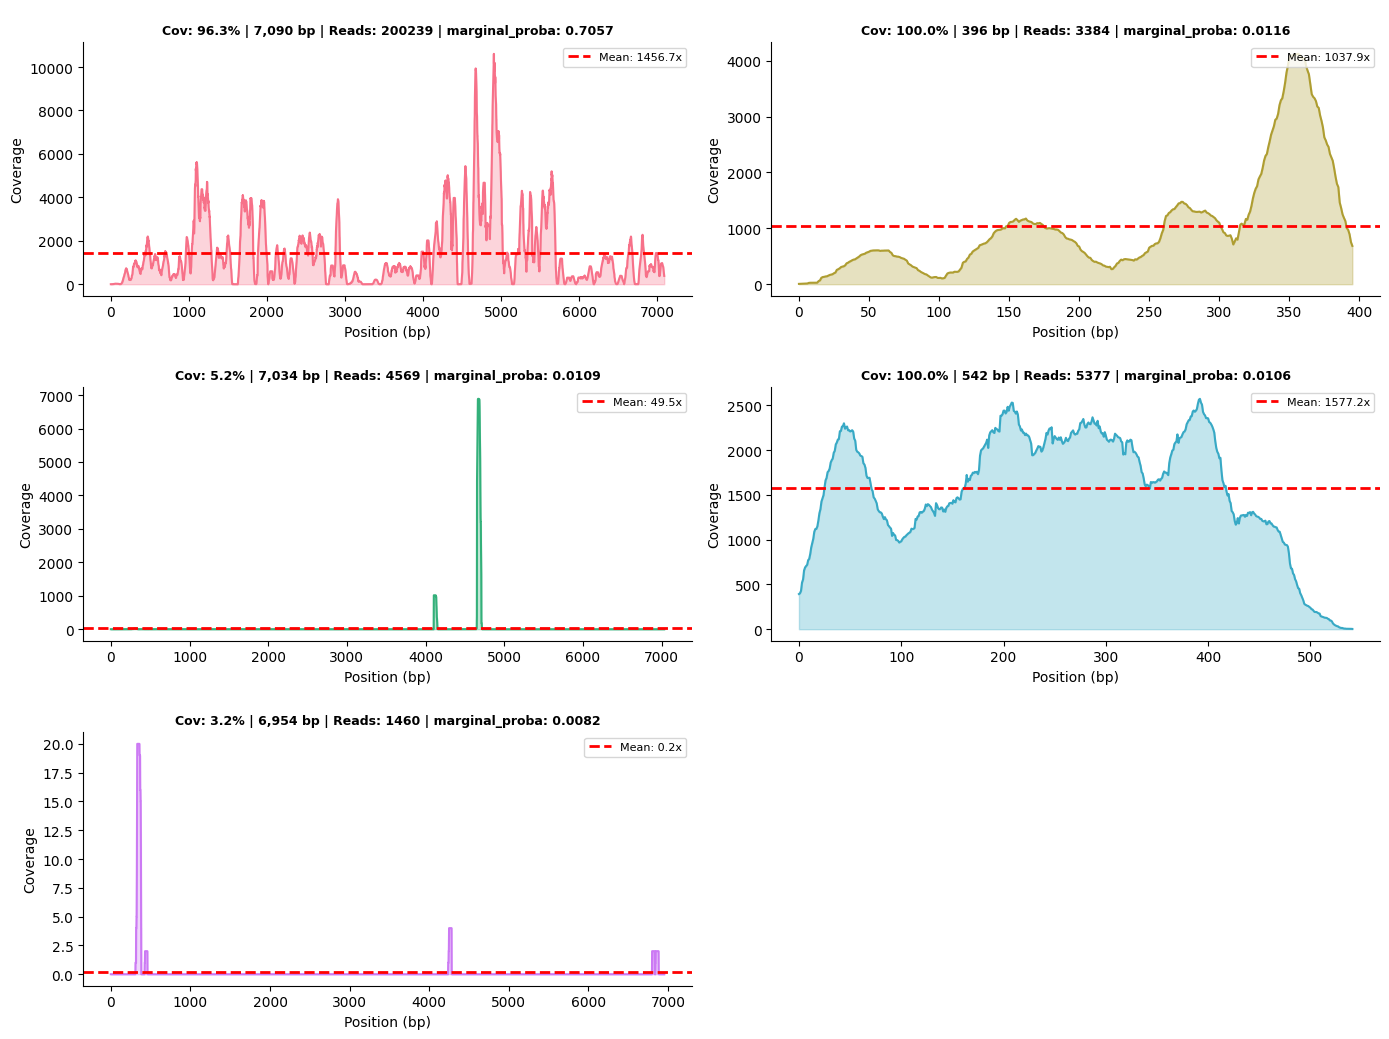

In [95]:
trident.pl.coverage(acc_adata, top_n=5, by="marginal_proba", save_path="figures/coverage_by_mp.png")

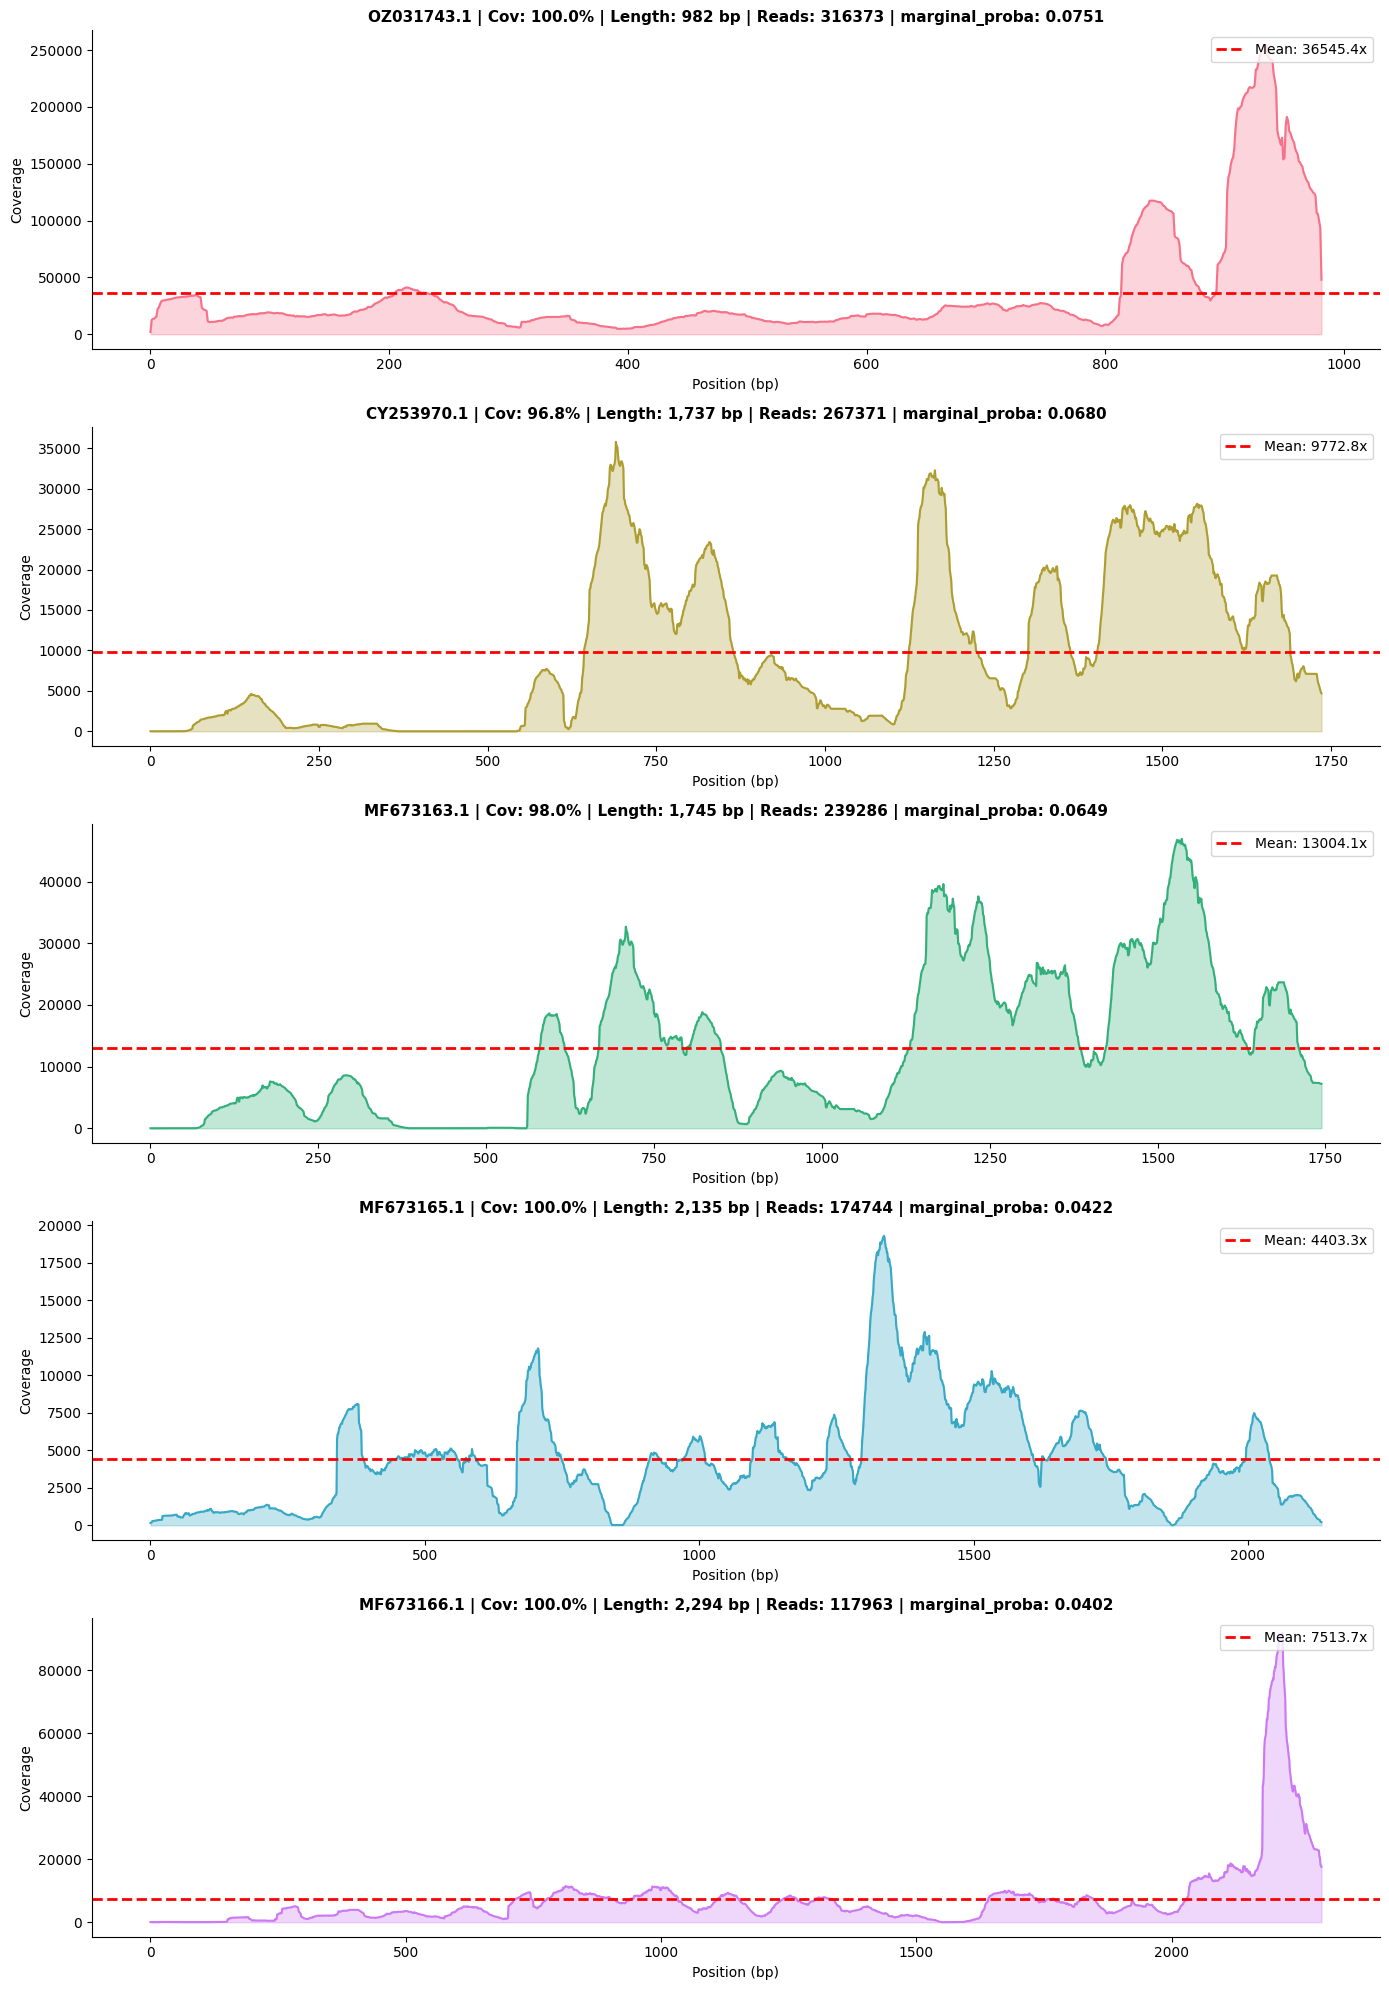

In [7]:
trident.pl.coverage(acc_adata, top_n=5, by="marginal_proba", save_path="figures/coverage_by_mp.png")

In [115]:
trident.pl.read_cluster(
    acc_adata,
    n_reads_subsample=1000,
    top_n_var=30,
    method="average",
    metric="correlation",
    mode="silhouette",
    kmax=5,
    standardize="zscore_rows",
)

ValueError: No trident metadata found in adata.uns.

In [23]:
trident.tl.cluster_consensus(acc_adata)

2026-04-22 22:25:26,738 | INFO : Processing cluster 1
2026-04-22 22:25:26,760 | INFO :   57219 reads
2026-04-22 22:25:46 - MEGAHIT v1.2.9
2026-04-22 22:25:46 - Using megahit_core with POPCNT and BMI2 support
2026-04-22 22:25:46 - Convert reads to binary library
2026-04-22 22:25:46 - b'INFO  sequence/io/sequence_lib.cpp  :   75 - Lib 0 (/shares/swabseq/trident_globals/0139101_F8_25110500714_S62_R1_001/cluster_1.fastq): se, 114438 reads, 51 max length'
2026-04-22 22:25:46 - b'INFO  utils/utils.h                 :  152 - Real: 0.0581\tuser: 0.0420\tsys: 0.0153\tmaxrss: 13700'
2026-04-22 22:25:46 - k-max reset to: 59 
2026-04-22 22:25:46 - Start assembly. Number of CPU threads 31 
2026-04-22 22:25:46 - k list: 21,29,39,59 
2026-04-22 22:25:46 - Memory used: 118898646220
2026-04-22 22:25:46 - Extract solid (k+1)-mers for k = 21 
2026-04-22 22:25:47 - Build graph for k = 21 
2026-04-22 22:25:47 - Assemble contigs from SdBG for k = 21
2026-04-22 22:25:47 - Local assembly for k = 21
2026-04-22

In [24]:
contigs = trident.tl.blast_contigs(acc_adata)

BLASTing cluster_1_k39_4 flag=1 multi=1819.0000 len=1535...
  RID: YKBFGCKB016, estimated wait: 30s
  Top hit: PZ048382 | Influenza A virus (A/Washington/WA-UW-44382/2026(H3N2)) segment 5 nucleocapsid protein (NP) gene, partial cds | e=0 | 100.0% id | 99.0% cov
BLASTing cluster_2_k39_18 flag=1 multi=5.0000 len=268...
  RID: YKBGP0RB016, estimated wait: 30s
  Top hit: PZ005067 | Influenza A virus (A/Oregon/71/2025(H3N2)) segment 6 neuraminidase (NA) gene, complete cds &gt;gi|3198458584|gb|PZ048389.1| Influenza A virus (A/Washington/WA-UW-44382/2026(H3N2)) segment 6 neuraminidase (NA) gene, complete cds | e=3.4052e-106 | 100.0% id | 82.1% cov
BLASTing cluster_2_k39_23 flag=1 multi=6.0000 len=237...
  RID: YKBHWJF5014, estimated wait: 30s
  Top hit: LT727009 | Vector pMS27, complete sequence | e=1.74767e-115 | 100.0% id | 100.0% cov
BLASTing cluster_2_k39_10 flag=1 multi=3.0000 len=249...
  RID: YKBK1XXG014, estimated wait: 30s
  Top hit: PZ048383 | Influenza A virus (A/Washington/WA-UW-4

In [25]:
for c in contigs:
    print(c.blast_closest_taxids)

['11320', '11320', '11320', '11320', '11320']


,accession,seq_len,L,taxid,name,"sum_r(X_r,t)",composite_score,phi,pi,accession_cluster,accession_cluster_color,accession_cluster_lca,marginal_proba


['11320', '11320', '11320', '11320', '11320']


,accession,seq_len,L,taxid,name,"sum_r(X_r,t)",composite_score,phi,pi,accession_cluster,accession_cluster_color,accession_cluster_lca,marginal_proba


['1945352', '1945236', '1944690', '1944689', '12022']


...

,accession,seq_len,L,taxid,name,"sum_r(X_r,t)",composite_score,phi,pi,accession_cluster,accession_cluster_color,accession_cluster_lca,marginal_proba


['11320', '11320', '11320', '11320', '11320']


,accession,seq_len,L,taxid,name,"sum_r(X_r,t)",composite_score,phi,pi,accession_cluster,accession_cluster_color,accession_cluster_lca,marginal_proba


['11320', '11320', '11320', '11320', '11320']


,accession,seq_len,L,taxid,name,"sum_r(X_r,t)",composite_score,phi,pi,accession_cluster,accession_cluster_color,accession_cluster_lca,marginal_proba
